In [1]:
from Distributions import GP_Regression, multivariate_normal
from ADPestimators import First_Est
import numpy.random as nr

from ADPIMH import BAIM, adp_only
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
distribution1 = "multivariate_normal"
distribution2 = "GP_Regression"
proposal = distribution1 
target = distribution2

lr_burnin = 0.01                     # learning rate
Itr_burnin = 200000                  # Number of iterations of MCMC
batch_size_burnin = 50

lr = 0.005
Itr = 12000
batch_size = 100

data = 'pendulum' # 'boston' 'bodyfat' 'pendulum'

In [3]:
est = GP_Regression()
est.load_data(data)
d = 3
mu1 = None
L1 = None
mu2 = np.ones(d)
L2 = np.eye(d)

I0000 00:00:1698339899.135991    8838 tfrt_cpu_pjrt_client.cc:349] TfrtCpuClient created.


1000/1000 batches adapted !

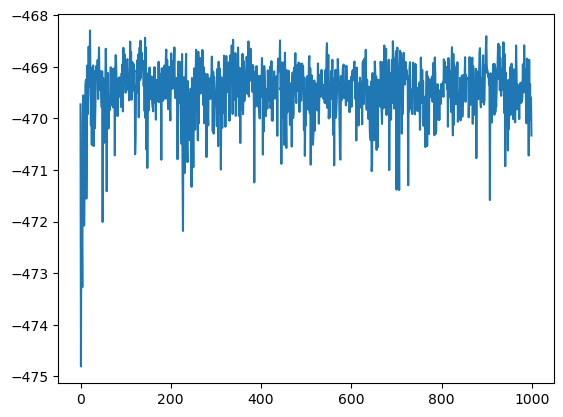

600/600 batches adapted !

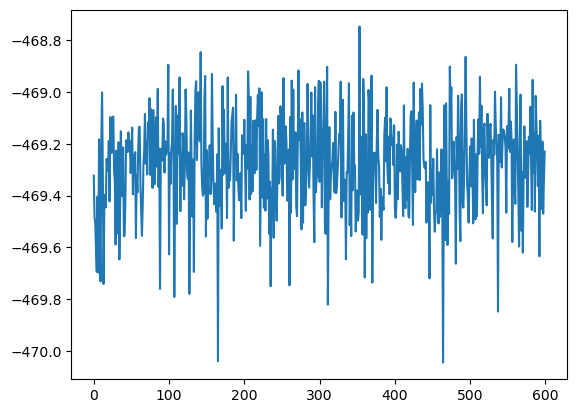

In [8]:
lr_fast = 0.01                     # learning rate
Itr_fast = 10000                  # Number of iterations of MCMC
batch_size_fast = 10
Myadpfast = adp_only(target, proposal,Itr_fast, batch_size_fast ,d, lr_fast,est)
Myadpfast.set_distribution_parameters(mu1,L1,mu2,L2)
resul1 = Myadpfast.adp(True)
plt.plot(resul1)
plt.show()
mu2 = Myadpfast.p_mean
L2 = Myadpfast.p_L

lr_burnin = 0.005                     # learning rate
Itr_burnin = 30000                  # Number of iterations of MCMC
batch_size_burnin = 50
Myadp = adp_only(target, proposal,Itr_burnin, batch_size_burnin,d,lr_burnin,est)
Myadp.set_distribution_parameters(mu1,L1,mu2,L2)
resul1 = Myadp.adp(True)
plt.plot(resul1)
plt.show()
mu2 = Myadp.p_mean
L2 = Myadp.p_L

# lr_burnin = 0.00005                     # learning rate
# Itr_burnin = 20000                  # Number of iterations of MCMC
# batch_size_burnin = 100
# Myadp = adp_only(target, proposal,Itr_burnin, batch_size_burnin,d,lr_burnin,est)
# Myadp.set_distribution_parameters(mu1,L1,mu2,L2)
# resul1 = Myadp.adp(True)
# plt.plot(resul1)
# plt.show()
# mu2 = Myadp.p_mean
# L2 = Myadp.p_L

In [9]:
print(mu2)

[ 1.0299146  2.607025  -9.146141 ]


In [10]:
results = []
epoch = 10

lr = 0.00005
batch_size = 100
Sample_N = batch_size * 20
Itr = Sample_N+1000

for i in range(epoch):
    print('\n',i + 1, ' th epoch')
    MyIMHpre2 = BAIM(target, proposal, Itr, batch_size, d, lr, est, df = 2, value = i + 10)
    MyIMHpre2.set_distribution_parameters(mu1, L1, mu2, L2)
    resul2 = MyIMHpre2.adpIMH()
    results.append(resul2)


 1  th epoch
30/30 batches adapted !
 2  th epoch
30/30 batches adapted !
 3  th epoch
30/30 batches adapted !
 4  th epoch
30/30 batches adapted !
 5  th epoch
30/30 batches adapted !
 6  th epoch
30/30 batches adapted !
 7  th epoch
30/30 batches adapted !
 8  th epoch
30/30 batches adapted !
 9  th epoch
30/30 batches adapted !
 10  th epoch
30/30 batches adapted !

In [11]:
Ans = np.zeros((epoch,d ))
Ans2= np.zeros((epoch,d ))
accm = np.zeros((epoch,1))
for i in range(epoch):
    A = results[i][0]
    B = results[i][1]
    C = results[i][2]
    D = results[i][3]
    E = results[i][6]
    accm[i] = np.mean(E)
# Ess = tfp.mcmc.effective_sample_size(tf.convert_to_tensor(A))
# print(Ess)
    for j in range(d):
        Esti = First_Est(Sample_N, batch_size, j)
        Esti.sample_loader(A,B,C,D[0])
        Ans2[i,j] = Esti.BatchIMCV2()[0]
        Ans[i,j] = Esti.IM()[0]

accm_mean = accm.mean()
VRF2 = Ans.var(axis = 0) / Ans2.var(axis = 0)
print(accm.mean())

print(VRF2)

print(min(VRF2[0:d-1]), max(VRF2[0:d-1]))

print(Ans.mean(axis = 0))
print(Ans2.mean(axis = 0))

0.8907666666666667
[10.05778599 10.26574634 21.04420585]
10.057785989641898 10.265746336102673
[ 1.02733968  2.61027189 -9.09641603]
[ 0.97537373  2.4783288  -8.64165407]


In [12]:
hyperpara = Ans2.mean(axis = 0)

In [ ]:
a = np.array([1,2,3,4,5,6,7,8,9]).reshape(3,3)
b = np.expand_dims(a, axis=0).repeat(3, axis=0)
c = np.expand_dims(a, axis=0).repeat(3, axis=0).transpose(1,0,2)
seq = np.array([1,0.5,100])
print(b-c)
print((b-c)/seq)
d = np.sum((b-c)/seq, axis = 2)

print(d)
